# Homework 5.1 - Steps 6-10: Decoder, Training, Evaluation, and Failure Analysis

This notebook performs Tasks 6 through 10 as one experiment pipeline.

It:

1. learns fixed English statistics from *The Republic*,
2. performs a classical substitution-inference stage using only permitted information,
3. builds an embedding plus multilayer-perceptron neural decoder,
4. compares Republic-informed training with anchor-only training,
5. varies anchor percentage, context window size, and decoder size,
6. records the number of trainable parameters,
7. evaluates only after the models and training procedures are fixed,
8. reports all-token accuracy, unanchored-token accuracy, and hidden-map recovery,
9. saves the requested plots,
10. identifies observed failure modes separately from untested hypotheses.

No Transformer or attention layer is used.

## Information restriction

Before final evaluation, this notebook is allowed to read only:

- the training glyph sequence,
- the validation glyph sequence,
- the revealed anchor pairs for the selected anchor percentage,
- the independent *Republic* syllable sequence,
- the source vocabulary.

The hidden plaintext map is not loaded during inference, neural training, validation, early stopping, or hyperparameter definition.

The hidden map is loaded only after all experiment configurations have been fixed and trained. It is then used for final evaluation.

The test sequence is not used during training or validation.

## Two-stage decipherment model

This notebook uses the two-stage approach permitted by the assignment.

### Stage A: classical inference from *Republic*

The *Republic* corpus is used to estimate a fixed smoothed bigram model over source syllables.

For source syllables $$a,b\in T$$,

$$
P_R(b\mid a)
=
\frac{C_R(a,b)+\alpha}
{C_R(a)+\alpha K}.
$$

For a candidate glyph-to-token map $$\pi:G\rightarrow T$$, the training glyph sequence supplies glyph bigram counts $$C_G(g,h)$$.

We score a candidate map using

$$
S(\pi)
=
\sum_{g,h}
C_G(g,h)
\log P_R(\pi(h)\mid \pi(g)).
$$

The revealed anchors are fixed constraints. The remaining mapping is initialized using frequency ranks and then improved by seeded swap optimization of frequent unanchored glyphs.

The English statistics are frozen before decoder training and remain fixed across all comparisons.

### Stage B: neural decoder

After Stage A produces an inferred map, the Republic-informed neural decoder is trained to reproduce that inferred map from a local glyph window.

Therefore this is explicitly a two-stage method. The neural decoder does not itself perform the original decipherment.

For comparison, the anchor-only decoder is trained only on positions whose center glyph is revealed by the anchor set.

## Neural decoder

For context radius $$m$$, the input is

$$
y_{i-m},\ldots,y_i,\ldots,y_{i+m}.
$$

Each glyph ID is embedded, the embeddings are concatenated, and the result is passed through a multilayer perceptron.

The output is a distribution over the $$K$$ possible source syllable tokens:

$$
P_\theta(x_i\mid y_{i-m},\ldots,y_{i+m}).
$$

The training loss is ordinary cross-entropy.

For the anchor-only model,

$$
L_{\text{anchor}}
=
-\frac{1}{|I_A|}
\sum_{i\in I_A}
\log P_\theta(a(y_i)\mid y_{i-m:i+m}),
$$

where $$I_A$$ contains training positions whose center glyph is anchored.

For the Republic-informed two-stage model,

$$
L_{\text{informed}}
=
-\frac{1}{|I|}
\sum_{i\in I}
\log P_\theta(\widehat{\pi}(y_i)\mid y_{i-m:i+m}),
$$

where $$\widehat{\pi}$$ is the candidate map inferred in Stage A.

The hidden true map is not used in either training loss.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import copy
import csv
import math
import random
import re

import numpy as np
import matplotlib.pyplot as plt

try:
    import torch
    from torch import nn
    from torch.utils.data import Dataset, DataLoader
except ImportError as exc:
    raise ImportError(
        "PyTorch is required for Steps 6-10. "
        "Install torch in the notebook environment and rerun."
    ) from exc

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd
DATA_DIR = PROJECT_ROOT / "data"
RESULT_IMAGE_DIR = PROJECT_ROOT / "result images"

DECIPHER_DIR = DATA_DIR / "decipherment_inputs"
SPLIT_DIR = DECIPHER_DIR / "splits"
ANCHOR_DIR = DECIPHER_DIR / "anchors"
EVALUATION_DIR = DATA_DIR / "evaluation_only"

SOURCE_VOCAB_PATH = DATA_DIR / "source_syllable_vocabulary.csv"
REPUBLIC_SEQUENCE_PATH = DATA_DIR / "republic_syllable_token_sequence.csv"

TRAIN_PATH = SPLIT_DIR / "train_glyph_sequence.csv"
VALIDATION_PATH = SPLIT_DIR / "validation_glyph_sequence.csv"
TEST_PATH = SPLIT_DIR / "test_glyph_sequence.csv"

HIDDEN_MAP_PATH = EVALUATION_DIR / "hidden_syllable_glyph_bijection.csv"

INFERRED_MAP_DIR = DATA_DIR / "inferred_maps"
MODEL_DIR = DATA_DIR / "trained_models"

RESULT_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
INFERRED_MAP_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

for path in [
    SOURCE_VOCAB_PATH,
    REPUBLIC_SEQUENCE_PATH,
    TRAIN_PATH,
    VALIDATION_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing required fitting input: {path}\n"
            "Run the corrected Steps 1-5 first."
        )

print("PyTorch version:", torch.__version__)
print("Result-image folder:", RESULT_IMAGE_DIR.resolve())

PyTorch version: 2.1.0+cu118
Result-image folder: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\result images


## Fixed experiment settings

In [2]:
GLOBAL_SEED = 638610

ANCHOR_PERCENTAGES = [5, 10, 20, 40]
CONTEXT_RADII = [1, 2, 4]

DECODER_SIZES = {
    "small": {
        "embedding_dim": 16,
        "hidden_dim": 64,
    },
    "medium": {
        "embedding_dim": 32,
        "hidden_dim": 128,
    },
    "large": {
        "embedding_dim": 64,
        "hidden_dim": 256,
    },
}

BASE_ANCHOR_PERCENTAGE = 20
BASE_CONTEXT_RADIUS = 2
BASE_DECODER_SIZE = "medium"

REFERENCE_SMOOTHING_ALPHA = 0.10

# Classical inference settings.
INFERENCE_TOP_N = 200
INFERENCE_SWAP_STEPS = 6000
INFERENCE_T_START = 0.005
INFERENCE_T_END = 0.00001

# Neural training settings.
MAX_EPOCHS = 8
PATIENCE = 2
BATCH_SIZE = 1024
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GLOBAL_SEED)

print("Device:", DEVICE)
print("All experiment settings are fixed before test evaluation.")

Device: cuda
All experiment settings are fixed before test evaluation.


## Load the source vocabulary

In [3]:
source_rows = []

with SOURCE_VOCAB_PATH.open("r", encoding="utf-8", newline="") as f:
    reader = csv.DictReader(f)

    for row in reader:
        source_rows.append({
            "source_id": int(row["source_id"]),
            "syllable": row["syllable"],
        })

source_rows.sort(key=lambda r: r["source_id"])

K = len(source_rows)

assert [r["source_id"] for r in source_rows] == list(range(K))
assert len({r["syllable"] for r in source_rows}) == K

source_id_by_syllable = {
    row["syllable"]: row["source_id"]
    for row in source_rows
}

syllable_by_source_id = {
    row["source_id"]: row["syllable"]
    for row in source_rows
}

print("Source vocabulary size K:", f"{K:,}")

Source vocabulary size K: 3,052


## Load training and validation glyph sequences

The test glyph sequence is deliberately not loaded here. It remains unavailable until all models and hyperparameters are fixed.

In [4]:
def load_glyph_sequence(path):
    sequence = []

    with path.open("r", encoding="utf-8", newline="") as f:
        reader = csv.DictReader(f)

        for expected_position, row in enumerate(reader):
            partition_position = int(row["partition_position"])
            glyph_id = int(row["glyph_id"])

            assert partition_position == expected_position
            sequence.append(glyph_id)

    return np.asarray(sequence, dtype=np.int64)


train_sequence = load_glyph_sequence(TRAIN_PATH)
validation_sequence = load_glyph_sequence(VALIDATION_PATH)

for name, sequence in [
    ("train", train_sequence),
    ("validation", validation_sequence),
]:
    assert sequence.min() >= 0
    assert sequence.max() < K
    print(name, "tokens:", f"{len(sequence):,}")

train tokens: 54,082
validation tokens: 11,589


## Load the permitted anchor files

In [5]:
anchor_maps = {}

for percentage in ANCHOR_PERCENTAGES:
    path = ANCHOR_DIR / f"anchors_{percentage:02d}.csv"

    if not path.exists():
        raise FileNotFoundError(
            f"Missing anchor file: {path}\n"
            "Run Steps 4-5 first."
        )

    mapping = {}

    with path.open("r", encoding="utf-8", newline="") as f:
        reader = csv.DictReader(f)

        for row in reader:
            glyph_id = int(row["glyph_id"])
            source_id = int(row["source_id"])
            syllable = row["syllable"]

            assert source_id_by_syllable[syllable] == source_id
            mapping[glyph_id] = source_id

    anchor_maps[percentage] = mapping

    print(
        f"{percentage:>2}% anchors:",
        f"{len(mapping):,}",
        f"({100*len(mapping)/K:.4f}% actual)",
    )

for small, large in zip(ANCHOR_PERCENTAGES[:-1], ANCHOR_PERCENTAGES[1:]):
    assert set(anchor_maps[small]).issubset(set(anchor_maps[large]))

print("Nested anchor sets verified.")

 5% anchors: 153 (5.0131% actual)
10% anchors: 305 (9.9934% actual)
20% anchors: 610 (19.9869% actual)
40% anchors: 1,221 (40.0066% actual)
Nested anchor sets verified.


## Build the fixed *Republic* reference statistics

Only syllables that belong to the source vocabulary $$T$$ can be decoder outputs.

A *Republic* syllable that is not in $$T$$ is not merged with any source token. It is simply outside the decoder output vocabulary.

Source syllables absent from *The Republic* receive zero empirical count and are handled by additive smoothing.

In [6]:
republic_source_ids = []

with REPUBLIC_SEQUENCE_PATH.open("r", encoding="utf-8", newline="") as f:
    reader = csv.DictReader(f)

    for row in reader:
        syllable = row["syllable"]
        source_id = source_id_by_syllable.get(syllable)
        republic_source_ids.append(source_id)

reference_frequency = np.zeros(K, dtype=np.int64)
reference_outgoing = np.zeros(K, dtype=np.int64)
reference_bigram_counts = Counter()

for source_id in republic_source_ids:
    if source_id is not None:
        reference_frequency[source_id] += 1

for left, right in zip(republic_source_ids[:-1], republic_source_ids[1:]):
    if left is None or right is None:
        continue

    reference_bigram_counts[(left, right)] += 1
    reference_outgoing[left] += 1

REFERENCE_TOTAL_SOURCE_TOKENS = int(reference_frequency.sum())
REFERENCE_TOTAL_BIGRAMS = int(sum(reference_bigram_counts.values()))

def reference_log_probability(left_source_id, right_source_id):
    alpha = REFERENCE_SMOOTHING_ALPHA

    numerator = (
        reference_bigram_counts.get(
            (int(left_source_id), int(right_source_id)),
            0,
        )
        + alpha
    )

    denominator = (
        reference_outgoing[int(left_source_id)]
        + alpha * K
    )

    return math.log(numerator) - math.log(denominator)


print("Republic tokens belonging to T:", f"{REFERENCE_TOTAL_SOURCE_TOKENS:,}")
print("Republic source-token bigrams:", f"{REFERENCE_TOTAL_BIGRAMS:,}")
print("Source syllables observed in Republic:", f"{np.count_nonzero(reference_frequency):,}")
print("Source syllables absent from Republic:", f"{np.count_nonzero(reference_frequency == 0):,}")
print("Reference statistics are now fixed.")

Republic tokens belonging to T: 149,831
Republic source-token bigrams: 143,006
Source syllables observed in Republic: 2,240
Source syllables absent from Republic: 812
Reference statistics are now fixed.


## Build training-glyph statistics

In [7]:
training_glyph_frequency = np.bincount(
    train_sequence,
    minlength=K,
).astype(np.int64)

training_bigram_counts = Counter(
    zip(
        train_sequence[:-1].tolist(),
        train_sequence[1:].tolist(),
    )
)

training_bigram_total = int(sum(training_bigram_counts.values()))

incident_edges = [set() for _ in range(K)]

for edge in training_bigram_counts:
    left, right = edge
    incident_edges[left].add(edge)
    incident_edges[right].add(edge)

print("Training glyph bigrams:", f"{training_bigram_total:,}")
print("Distinct observed glyph bigrams:", f"{len(training_bigram_counts):,}")

Training glyph bigrams: 54,081
Distinct observed glyph bigrams: 20,320


## Classical Stage A: infer a candidate substitution map

In [8]:
def initialize_frequency_map(anchors):
    mapping = np.full(K, -1, dtype=np.int64)

    anchored_glyphs = set(anchors)
    anchored_tokens = set(anchors.values())

    for glyph_id, source_id in anchors.items():
        mapping[glyph_id] = source_id

    unanchored_glyphs = [
        glyph_id
        for glyph_id in range(K)
        if glyph_id not in anchored_glyphs
    ]

    unanchored_tokens = [
        source_id
        for source_id in range(K)
        if source_id not in anchored_tokens
    ]

    unanchored_glyphs.sort(
        key=lambda glyph_id: (
            -int(training_glyph_frequency[glyph_id]),
            glyph_id,
        )
    )

    unanchored_tokens.sort(
        key=lambda source_id: (
            -int(reference_frequency[source_id]),
            source_id,
        )
    )

    assert len(unanchored_glyphs) == len(unanchored_tokens)

    for glyph_id, source_id in zip(
        unanchored_glyphs,
        unanchored_tokens,
    ):
        mapping[glyph_id] = source_id

    assert np.all(mapping >= 0)
    assert len(set(mapping.tolist())) == K

    return mapping


def mapping_score(mapping):
    total = 0.0

    for (left_glyph, right_glyph), count in training_bigram_counts.items():
        left_token = mapping[left_glyph]
        right_token = mapping[right_glyph]

        total += count * reference_log_probability(
            left_token,
            right_token,
        )

    return total


def swap_delta(mapping, glyph_a, glyph_b):
    affected_edges = (
        incident_edges[glyph_a]
        | incident_edges[glyph_b]
    )

    token_a = int(mapping[glyph_a])
    token_b = int(mapping[glyph_b])

    old_score = 0.0
    new_score = 0.0

    def token_after_swap(glyph_id):
        if glyph_id == glyph_a:
            return token_b
        if glyph_id == glyph_b:
            return token_a
        return int(mapping[glyph_id])

    for left_glyph, right_glyph in affected_edges:
        count = training_bigram_counts[(left_glyph, right_glyph)]

        old_score += count * reference_log_probability(
            int(mapping[left_glyph]),
            int(mapping[right_glyph]),
        )

        new_score += count * reference_log_probability(
            token_after_swap(left_glyph),
            token_after_swap(right_glyph),
        )

    return new_score - old_score


def infer_candidate_map(anchor_percentage):
    anchors = anchor_maps[anchor_percentage]

    mapping = initialize_frequency_map(anchors)
    initial_score = mapping_score(mapping)
    current_score = initial_score

    best_mapping = mapping.copy()
    best_score = current_score

    anchored_glyphs = set(anchors)

    optimizable = [
        glyph_id
        for glyph_id in range(K)
        if glyph_id not in anchored_glyphs
    ]

    optimizable.sort(
        key=lambda glyph_id: (
            -int(training_glyph_frequency[glyph_id]),
            glyph_id,
        )
    )

    optimizable = optimizable[:min(INFERENCE_TOP_N, len(optimizable))]

    if len(optimizable) < 2:
        return best_mapping, initial_score, best_score

    rng = np.random.default_rng(
        GLOBAL_SEED + 1000 + anchor_percentage
    )

    for step in range(INFERENCE_SWAP_STEPS):
        glyph_a, glyph_b = rng.choice(
            optimizable,
            size=2,
            replace=False,
        )

        glyph_a = int(glyph_a)
        glyph_b = int(glyph_b)

        delta = swap_delta(
            mapping,
            glyph_a,
            glyph_b,
        )

        progress = (
            step / max(1, INFERENCE_SWAP_STEPS - 1)
        )

        temperature = (
            INFERENCE_T_START
            * (
                INFERENCE_T_END / INFERENCE_T_START
            ) ** progress
        )

        normalized_delta = (
            delta / max(1, training_bigram_total)
        )

        accept = (
            delta >= 0
            or rng.random()
            < math.exp(
                max(-50.0, normalized_delta / temperature)
            )
        )

        if accept:
            mapping[glyph_a], mapping[glyph_b] = (
                mapping[glyph_b],
                mapping[glyph_a],
            )

            current_score += delta

            if current_score > best_score:
                best_score = current_score
                best_mapping = mapping.copy()

    # Verify all anchor constraints and the bijection.
    for glyph_id, source_id in anchors.items():
        assert int(best_mapping[glyph_id]) == int(source_id)

    assert len(set(best_mapping.tolist())) == K

    return best_mapping, initial_score, best_score

## Infer and save one candidate map for each anchor percentage

In [9]:
inferred_maps = {}
inference_records = []

for percentage in ANCHOR_PERCENTAGES:
    inferred_map, initial_score, final_score = infer_candidate_map(
        percentage
    )

    inferred_maps[percentage] = inferred_map

    path = INFERRED_MAP_DIR / f"inferred_map_{percentage:02d}.csv"

    with path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)

        writer.writerow([
            "glyph_id",
            "inferred_source_id",
            "inferred_syllable",
            "is_anchor",
        ])

        anchors = anchor_maps[percentage]

        for glyph_id in range(K):
            source_id = int(inferred_map[glyph_id])

            writer.writerow([
                glyph_id,
                source_id,
                syllable_by_source_id[source_id],
                glyph_id in anchors,
            ])

    inference_records.append({
        "anchor_percentage": percentage,
        "initial_bigram_score": initial_score,
        "final_bigram_score": final_score,
        "score_improvement": final_score - initial_score,
        "optimized_unanchored_top_n": min(
            INFERENCE_TOP_N,
            K - len(anchor_maps[percentage]),
        ),
        "swap_steps": INFERENCE_SWAP_STEPS,
    })

    print(
        f"{percentage:>2}% anchors: "
        f"initial score={initial_score:,.2f}, "
        f"final score={final_score:,.2f}, "
        f"improvement={final_score-initial_score:,.2f}"
    )

INFERENCE_SUMMARY_PATH = DATA_DIR / "task7_classical_inference_summary.csv"

with INFERENCE_SUMMARY_PATH.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(inference_records[0].keys()),
    )
    writer.writeheader()
    writer.writerows(inference_records)

print()
print("Saved:", INFERENCE_SUMMARY_PATH.resolve())
print("No hidden true map has been loaded.")

 5% anchors: initial score=-419,269.23, final score=-388,192.90, improvement=31,076.34
10% anchors: initial score=-417,339.60, final score=-387,418.01, improvement=29,921.60
20% anchors: initial score=-408,839.88, final score=-379,703.88, improvement=29,136.00
40% anchors: initial score=-399,133.41, final score=-368,584.66, improvement=30,548.75

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\data\task7_classical_inference_summary.csv
No hidden true map has been loaded.


## Neural Stage B: dataset and decoder definitions

In [10]:
class GlyphWindowDataset(Dataset):
    def __init__(
        self,
        sequence,
        context_radius,
        label_map,
        labeled_centers_only,
    ):
        self.sequence = np.asarray(
            sequence,
            dtype=np.int64,
        )

        self.m = int(context_radius)
        self.label_map = np.asarray(
            label_map,
            dtype=np.int64,
        )

        positions = np.arange(
            self.m,
            len(self.sequence) - self.m,
            dtype=np.int64,
        )

        if labeled_centers_only:
            center_glyphs = self.sequence[positions]
            keep = self.label_map[center_glyphs] >= 0
            positions = positions[keep]

        else:
            center_glyphs = self.sequence[positions]

            if np.any(self.label_map[center_glyphs] < 0):
                raise ValueError(
                    "Full-position training requires a label for every center glyph."
                )

        self.positions = positions

    def __len__(self):
        return len(self.positions)

    def __getitem__(self, index):
        position = int(self.positions[index])

        window = self.sequence[
            position - self.m:
            position + self.m + 1
        ]

        center_glyph = int(self.sequence[position])
        label = int(self.label_map[center_glyph])

        return (
            torch.as_tensor(
                window,
                dtype=torch.long,
            ),
            torch.tensor(
                label,
                dtype=torch.long,
            ),
        )


class GlyphDecoderMLP(nn.Module):
    def __init__(
        self,
        vocabulary_size,
        context_radius,
        embedding_dim,
        hidden_dim,
    ):
        super().__init__()

        self.vocabulary_size = vocabulary_size
        self.context_radius = context_radius

        window_width = 2 * context_radius + 1

        self.embedding = nn.Embedding(
            vocabulary_size,
            embedding_dim,
        )

        self.network = nn.Sequential(
            nn.Linear(
                window_width * embedding_dim,
                hidden_dim,
            ),
            nn.ReLU(),
            nn.Linear(
                hidden_dim,
                vocabulary_size,
            ),
        )

    def forward(self, windows):
        embedded = self.embedding(windows)
        flattened = embedded.flatten(start_dim=1)
        return self.network(flattened)


def count_trainable_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

## Neural training function

In [11]:
def set_training_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def make_label_map(
    method,
    anchor_percentage,
):
    if method == "anchor_only":
        label_map = np.full(
            K,
            -1,
            dtype=np.int64,
        )

        for glyph_id, source_id in anchor_maps[
            anchor_percentage
        ].items():
            label_map[glyph_id] = source_id

        labeled_centers_only = True

    elif method == "republic_informed":
        label_map = inferred_maps[
            anchor_percentage
        ].copy()

        labeled_centers_only = False

    else:
        raise ValueError(f"Unknown method: {method}")

    return label_map, labeled_centers_only


def evaluate_validation_loss(
    model,
    loader,
    loss_function,
):
    model.eval()

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():
        for windows, labels in loader:
            windows = windows.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(windows)
            loss = loss_function(
                logits,
                labels,
            )

            batch_size = labels.shape[0]

            total_loss += (
                float(loss.item())
                * batch_size
            )

            total_examples += batch_size

    return total_loss / max(1, total_examples)


def train_decoder(
    method,
    anchor_percentage,
    context_radius,
    decoder_size_name,
):
    size = DECODER_SIZES[decoder_size_name]

    seed = (
        GLOBAL_SEED
        + 10000
        + 100 * anchor_percentage
        + 10 * context_radius
        + list(DECODER_SIZES).index(decoder_size_name)
        + (0 if method == "anchor_only" else 5000)
    )

    set_training_seed(seed)

    label_map, labeled_centers_only = make_label_map(
        method,
        anchor_percentage,
    )

    train_dataset = GlyphWindowDataset(
        train_sequence,
        context_radius,
        label_map,
        labeled_centers_only,
    )

    validation_dataset = GlyphWindowDataset(
        validation_sequence,
        context_radius,
        label_map,
        labeled_centers_only,
    )

    if len(train_dataset) == 0:
        raise ValueError(
            f"No training positions for {method}, "
            f"{anchor_percentage}% anchors."
        )

    if len(validation_dataset) == 0:
        raise ValueError(
            f"No validation positions for {method}, "
            f"{anchor_percentage}% anchors."
        )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    model = GlyphDecoderMLP(
        vocabulary_size=K,
        context_radius=context_radius,
        embedding_dim=size["embedding_dim"],
        hidden_dim=size["hidden_dim"],
    ).to(DEVICE)

    parameter_count = count_trainable_parameters(
        model
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    loss_function = nn.CrossEntropyLoss()

    best_validation_loss = float("inf")
    best_state = None
    epochs_without_improvement = 0
    best_epoch = None

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()

        for windows, labels in train_loader:
            windows = windows.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            logits = model(windows)
            loss = loss_function(
                logits,
                labels,
            )

            loss.backward()
            optimizer.step()

        validation_loss = evaluate_validation_loss(
            model,
            validation_loader,
            loss_function,
        )

        if validation_loss < best_validation_loss - 1e-6:
            best_validation_loss = validation_loss
            best_epoch = epoch
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            break

    if best_state is None:
        raise RuntimeError(
            "Training did not produce a best model state."
        )

    model.load_state_dict(best_state)

    model_filename = (
        f"{method}"
        f"_a{anchor_percentage:02d}"
        f"_m{context_radius}"
        f"_{decoder_size_name}.pt"
    )

    model_path = MODEL_DIR / model_filename

    torch.save(
        {
            "state_dict": best_state,
            "method": method,
            "anchor_percentage": anchor_percentage,
            "context_radius": context_radius,
            "decoder_size_name": decoder_size_name,
            "embedding_dim": size["embedding_dim"],
            "hidden_dim": size["hidden_dim"],
            "parameter_count": parameter_count,
            "best_validation_loss": best_validation_loss,
            "best_epoch": best_epoch,
            "seed": seed,
        },
        model_path,
    )

    return {
        "method": method,
        "anchor_percentage": anchor_percentage,
        "context_radius": context_radius,
        "window_width": 2 * context_radius + 1,
        "decoder_size": decoder_size_name,
        "embedding_dim": size["embedding_dim"],
        "hidden_dim": size["hidden_dim"],
        "trainable_parameters": parameter_count,
        "training_positions": len(train_dataset),
        "validation_positions": len(validation_dataset),
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "model_path": str(model_path.relative_to(PROJECT_ROOT)),
    }

## Define the requested sweeps

We vary the three required quantities using one-factor-at-a-time sweeps.

### Anchor sweep

$$
5\%,10\%,20\%,40\%
$$

with $$m=2$$ and the medium decoder.

### Context sweep

$$
m=1,2,4
$$

with 20% anchors and the medium decoder.

### Decoder-size sweep

Small, medium, and large decoders with 20% anchors and $$m=2$$.

Repeated configurations are trained only once.

In [12]:
experiment_configs = set()

for percentage in ANCHOR_PERCENTAGES:
    experiment_configs.add(
        (
            percentage,
            BASE_CONTEXT_RADIUS,
            BASE_DECODER_SIZE,
        )
    )

for context_radius in CONTEXT_RADII:
    experiment_configs.add(
        (
            BASE_ANCHOR_PERCENTAGE,
            context_radius,
            BASE_DECODER_SIZE,
        )
    )

for decoder_size_name in DECODER_SIZES:
    experiment_configs.add(
        (
            BASE_ANCHOR_PERCENTAGE,
            BASE_CONTEXT_RADIUS,
            decoder_size_name,
        )
    )

experiment_configs = sorted(
    experiment_configs,
    key=lambda item: (
        item[0],
        item[1],
        list(DECODER_SIZES).index(item[2]),
    ),
)

print("Unique configurations:", len(experiment_configs))

for config in experiment_configs:
    print(config)

Unique configurations: 8
(5, 2, 'medium')
(10, 2, 'medium')
(20, 1, 'medium')
(20, 2, 'small')
(20, 2, 'medium')
(20, 2, 'large')
(20, 4, 'medium')
(40, 2, 'medium')


## Train both methods for every fixed configuration

In [13]:
training_records = []

for (
    anchor_percentage,
    context_radius,
    decoder_size_name,
) in experiment_configs:

    for method in [
        "anchor_only",
        "republic_informed",
    ]:
        print()
        print(
            "Training:",
            method,
            f"anchors={anchor_percentage}%",
            f"m={context_radius}",
            f"size={decoder_size_name}",
        )

        record = train_decoder(
            method=method,
            anchor_percentage=anchor_percentage,
            context_radius=context_radius,
            decoder_size_name=decoder_size_name,
        )

        training_records.append(record)

        print(
            "  parameters:",
            f"{record['trainable_parameters']:,}",
        )
        print(
            "  best validation loss:",
            f"{record['best_validation_loss']:.6f}",
        )
        print(
            "  best epoch:",
            record["best_epoch"],
        )


TRAINING_MANIFEST_PATH = DATA_DIR / "task6_8_training_manifest.csv"

with TRAINING_MANIFEST_PATH.open(
    "w",
    newline="",
    encoding="utf-8",
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(training_records[0].keys()),
    )
    writer.writeheader()
    writer.writerows(training_records)

print()
print("All models are trained and fixed.")
print("Saved:", TRAINING_MANIFEST_PATH.resolve())
print("The hidden true map still has not been loaded.")


Training: anchor_only anchors=5% m=2 size=medium
  parameters: 511,980
  best validation loss: 4.958415
  best epoch: 8

Training: republic_informed anchors=5% m=2 size=medium
  parameters: 511,980
  best validation loss: 0.417341
  best epoch: 8

Training: anchor_only anchors=10% m=2 size=medium
  parameters: 511,980
  best validation loss: 3.140556
  best epoch: 8

Training: republic_informed anchors=10% m=2 size=medium
  parameters: 511,980
  best validation loss: 0.416231
  best epoch: 8

Training: anchor_only anchors=20% m=1 size=medium
  parameters: 503,788
  best validation loss: 1.845790
  best epoch: 8

Training: republic_informed anchors=20% m=1 size=medium
  parameters: 503,788
  best validation loss: 0.387443
  best epoch: 8

Training: anchor_only anchors=20% m=2 size=small
  parameters: 252,396
  best validation loss: 3.377391
  best epoch: 8

Training: republic_informed anchors=20% m=2 size=small
  parameters: 252,396
  best validation loss: 0.826216
  best epoch: 8

Tra

# Final evaluation begins here

Everything above this point uses only permitted fitting and validation information.

The model architectures, training procedure, classical inference procedure, context sizes, decoder sizes, anchor percentages, early-stopping rule, and saved model states are now fixed.

Only now are the held-out test glyph sequence and the hidden inverse map loaded for final evaluation. No model is retrained and no hyperparameter is changed after this point.

In [14]:
if not TEST_PATH.exists():
    raise FileNotFoundError(
        f"Missing held-out test glyph sequence: {TEST_PATH}"
    )

test_sequence = load_glyph_sequence(TEST_PATH)
assert test_sequence.min() >= 0
assert test_sequence.max() < K
print("Held-out test glyph sequence loaded only after fitting is fixed.")
print("test tokens:", f"{len(test_sequence):,}")

if not HIDDEN_MAP_PATH.exists():
    raise FileNotFoundError(
        f"Missing evaluation-only hidden map: {HIDDEN_MAP_PATH}"
    )

true_inverse_map = np.full(
    K,
    -1,
    dtype=np.int64,
)

with HIDDEN_MAP_PATH.open(
    "r",
    encoding="utf-8",
    newline="",
) as f:
    reader = csv.DictReader(f)

    for row in reader:
        glyph_id = int(row["glyph_id"])
        source_id = int(row["source_id"])

        true_inverse_map[glyph_id] = source_id

assert np.all(true_inverse_map >= 0)
assert len(set(true_inverse_map.tolist())) == K

print("Hidden inverse map loaded for final evaluation only.")

Held-out test glyph sequence loaded only after fitting is fixed.
test tokens: 11,589
Hidden inverse map loaded for final evaluation only.


## Test metrics

For each trained model we report:

1. token-level accuracy over every valid test center position,
2. token-level accuracy restricted to occurrences of unanchored glyphs,
3. recovery of the hidden inverse map.

Because a contextual decoder can predict different tokens for different occurrences of one glyph, the candidate inverse map is extracted by majority vote:

- collect all test predictions for one glyph type,
- choose the most frequently predicted source token,
- use that one token as the candidate translation of the glyph.

If a glyph never occurs at a valid test center, it is counted as unrecovered in the all-$$K$$ map-recovery metric.

We also report recovery restricted to glyph types observed at valid test centers and the corresponding type coverage.

In [15]:
class GlyphWindowInferenceDataset(Dataset):
    def __init__(
        self,
        sequence,
        context_radius,
    ):
        self.sequence = np.asarray(
            sequence,
            dtype=np.int64,
        )
        self.m = int(context_radius)

        self.positions = np.arange(
            self.m,
            len(self.sequence) - self.m,
            dtype=np.int64,
        )

    def __len__(self):
        return len(self.positions)

    def __getitem__(self, index):
        position = int(self.positions[index])

        window = self.sequence[
            position - self.m:
            position + self.m + 1
        ]

        center_glyph = int(
            self.sequence[position]
        )

        return (
            torch.as_tensor(
                window,
                dtype=torch.long,
            ),
            torch.tensor(
                center_glyph,
                dtype=torch.long,
            ),
        )


def load_saved_model(record):
    size = DECODER_SIZES[
        record["decoder_size"]
    ]

    model = GlyphDecoderMLP(
        vocabulary_size=K,
        context_radius=int(
            record["context_radius"]
        ),
        embedding_dim=size["embedding_dim"],
        hidden_dim=size["hidden_dim"],
    ).to(DEVICE)

    saved_path = Path(record["model_path"])
    if not saved_path.is_absolute():
        saved_path = PROJECT_ROOT / saved_path

    checkpoint = torch.load(
        saved_path,
        map_location=DEVICE,
    )

    model.load_state_dict(
        checkpoint["state_dict"]
    )

    model.eval()
    return model


def predict_test(model, context_radius):
    dataset = GlyphWindowInferenceDataset(
        test_sequence,
        context_radius,
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    all_center_glyphs = []
    all_predictions = []

    with torch.no_grad():
        for windows, center_glyphs in loader:
            windows = windows.to(DEVICE)

            logits = model(windows)
            predictions = torch.argmax(
                logits,
                dim=1,
            )

            all_center_glyphs.append(
                center_glyphs.numpy()
            )

            all_predictions.append(
                predictions.cpu().numpy()
            )

    return (
        np.concatenate(all_center_glyphs),
        np.concatenate(all_predictions),
    )


def candidate_map_from_votes(
    center_glyphs,
    predictions,
):
    votes = defaultdict(Counter)

    for glyph_id, prediction in zip(
        center_glyphs.tolist(),
        predictions.tolist(),
    ):
        votes[int(glyph_id)][
            int(prediction)
        ] += 1

    candidate_map = np.full(
        K,
        -1,
        dtype=np.int64,
    )

    for glyph_id, counter in votes.items():
        # Deterministic tie break: highest vote, then smallest source ID.
        best_token = min(
            counter,
            key=lambda token: (
                -counter[token],
                token,
            ),
        )

        candidate_map[glyph_id] = best_token

    return candidate_map


def evaluate_record(record):
    model = load_saved_model(record)

    center_glyphs, predictions = predict_test(
        model,
        int(record["context_radius"]),
    )

    truth = true_inverse_map[
        center_glyphs
    ]

    all_accuracy = float(
        np.mean(predictions == truth)
    )

    anchor_glyphs = set(
        anchor_maps[
            int(record["anchor_percentage"])
        ]
    )

    unanchored_mask = np.asarray(
        [
            int(glyph_id) not in anchor_glyphs
            for glyph_id in center_glyphs
        ],
        dtype=bool,
    )

    if np.any(unanchored_mask):
        unanchored_accuracy = float(
            np.mean(
                predictions[unanchored_mask]
                == truth[unanchored_mask]
            )
        )
    else:
        unanchored_accuracy = float("nan")

    candidate_map = candidate_map_from_votes(
        center_glyphs,
        predictions,
    )

    observed_mask = candidate_map >= 0

    map_recovery_all_K = float(
        np.mean(
            candidate_map
            == true_inverse_map
        )
    )

    if np.any(observed_mask):
        map_recovery_observed = float(
            np.mean(
                candidate_map[observed_mask]
                == true_inverse_map[observed_mask]
            )
        )
    else:
        map_recovery_observed = float("nan")

    type_coverage = float(
        np.mean(observed_mask)
    )

    inferred_map = inferred_maps[
        int(record["anchor_percentage"])
    ]

    classical_map_recovery_all_K = float(
        np.mean(
            inferred_map
            == true_inverse_map
        )
    )

    unanchored_glyph_mask = np.ones(
        K,
        dtype=bool,
    )

    unanchored_glyph_mask[
        list(anchor_glyphs)
    ] = False

    classical_map_recovery_unanchored = float(
        np.mean(
            inferred_map[
                unanchored_glyph_mask
            ]
            == true_inverse_map[
                unanchored_glyph_mask
            ]
        )
    )

    result = dict(record)

    result.update({
        "test_valid_positions": len(center_glyphs),
        "test_all_token_accuracy": all_accuracy,
        "test_unanchored_token_accuracy": unanchored_accuracy,
        "decoder_map_recovery_all_K": map_recovery_all_K,
        "decoder_map_recovery_observed_types": map_recovery_observed,
        "test_glyph_type_coverage": type_coverage,
        "classical_map_recovery_all_K": classical_map_recovery_all_K,
        "classical_map_recovery_unanchored": classical_map_recovery_unanchored,
    })

    return result

## Evaluate every fixed model exactly once

In [16]:
evaluation_records = []

for record in training_records:
    result = evaluate_record(record)
    evaluation_records.append(result)

    print(
        result["method"],
        f"a={result['anchor_percentage']}%",
        f"m={result['context_radius']}",
        result["decoder_size"],
        f"all={result['test_all_token_accuracy']:.4f}",
        f"unanchored={result['test_unanchored_token_accuracy']:.4f}",
        f"map={result['decoder_map_recovery_all_K']:.4f}",
    )


EVALUATION_RESULTS_PATH = DATA_DIR / "task9_evaluation_results.csv"

with EVALUATION_RESULTS_PATH.open(
    "w",
    newline="",
    encoding="utf-8",
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(
            evaluation_records[0].keys()
        ),
    )
    writer.writeheader()
    writer.writerows(evaluation_records)

print()
print("Saved:", EVALUATION_RESULTS_PATH.resolve())
print("Evaluation is complete. No retraining follows.")

anchor_only a=5% m=2 medium all=0.0307 unanchored=0.0000 map=0.0036
republic_informed a=5% m=2 medium all=0.0883 unanchored=0.0361 map=0.0216
anchor_only a=10% m=2 medium all=0.0459 unanchored=0.0000 map=0.0033
republic_informed a=10% m=2 medium all=0.1625 unanchored=0.0776 map=0.0413
anchor_only a=20% m=1 medium all=0.1472 unanchored=0.0000 map=0.0203
republic_informed a=20% m=1 medium all=0.2642 unanchored=0.0937 map=0.0675
anchor_only a=20% m=2 small all=0.0896 unanchored=0.0000 map=0.0046
republic_informed a=20% m=2 small all=0.2534 unanchored=0.0937 map=0.0472
anchor_only a=20% m=2 medium all=0.1436 unanchored=0.0000 map=0.0174
republic_informed a=20% m=2 medium all=0.2640 unanchored=0.0937 map=0.0685
anchor_only a=20% m=2 large all=0.1774 unanchored=0.0000 map=0.0433
republic_informed a=20% m=2 large all=0.2666 unanchored=0.0937 map=0.0744
anchor_only a=20% m=4 medium all=0.1435 unanchored=0.0000 map=0.0164
republic_informed a=20% m=4 medium all=0.2634 unanchored=0.0937 map=0.066

## Helper functions for the requested plots

In [17]:
def method_label(method):
    if method == "anchor_only":
        return "Anchor only"
    if method == "republic_informed":
        return "Republic informed"
    return method


def filtered_records(
    *,
    anchor_percentage=None,
    context_radius=None,
    decoder_size=None,
):
    rows = evaluation_records

    if anchor_percentage is not None:
        rows = [
            row for row in rows
            if int(row["anchor_percentage"])
            == int(anchor_percentage)
        ]

    if context_radius is not None:
        rows = [
            row for row in rows
            if int(row["context_radius"])
            == int(context_radius)
        ]

    if decoder_size is not None:
        rows = [
            row for row in rows
            if row["decoder_size"]
            == decoder_size
        ]

    return rows


def save_line_plot(
    rows,
    x_key,
    y_key,
    xlabel,
    ylabel,
    title,
    filename,
):
    plt.figure(figsize=(7, 5))

    for method in [
        "anchor_only",
        "republic_informed",
    ]:
        method_rows = [
            row for row in rows
            if row["method"] == method
        ]

        method_rows = sorted(
            method_rows,
            key=lambda row: float(
                row[x_key]
            ),
        )

        x = [
            float(row[x_key])
            for row in method_rows
        ]

        y = [
            float(row[y_key])
            for row in method_rows
        ]

        plt.plot(
            x,
            y,
            label=method_label(method),
        )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.tight_layout()

    output_path = (
        RESULT_IMAGE_DIR / filename
    )

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    print("Saved:", output_path.resolve())

## Accuracy versus anchor percentage

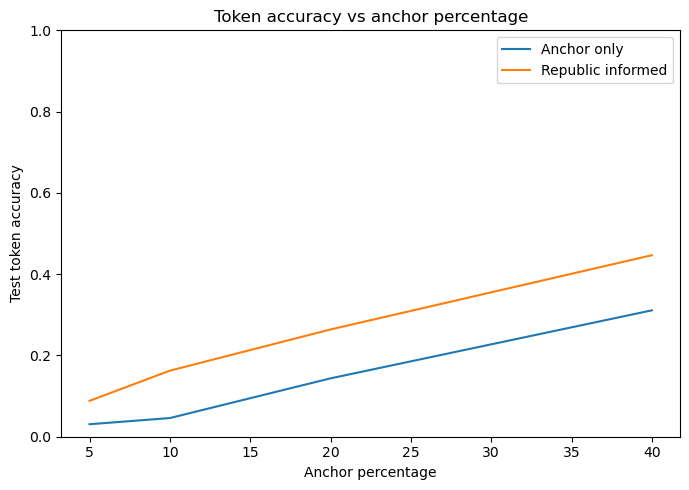

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\result images\token_accuracy_vs_anchor_percentage.png


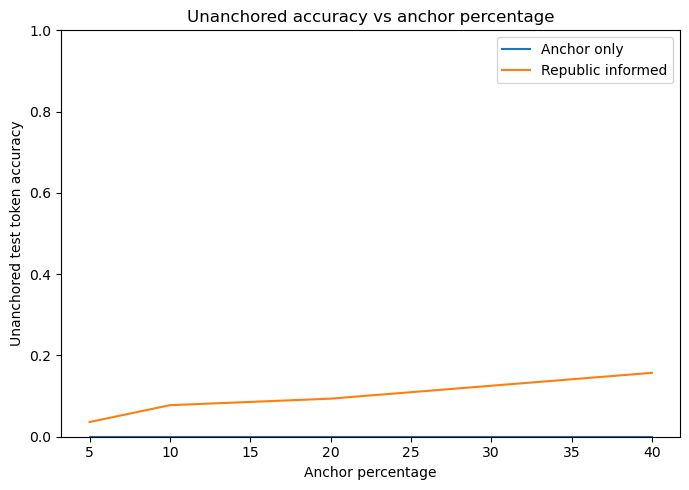

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\result images\unanchored_accuracy_vs_anchor_percentage.png


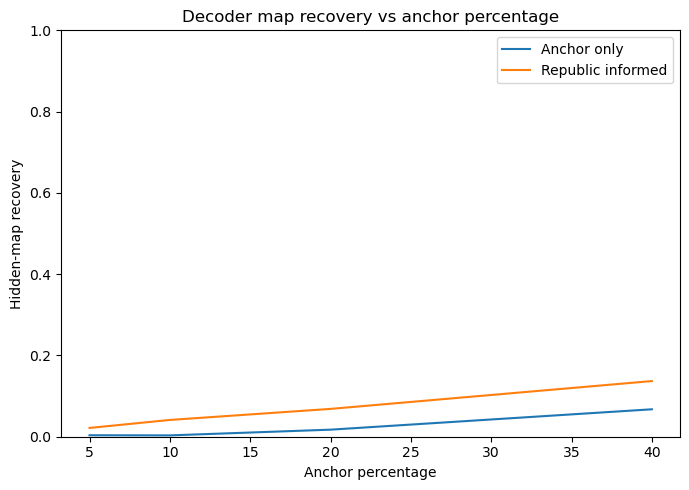

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\result images\map_recovery_vs_anchor_percentage.png


In [18]:
anchor_sweep_rows = filtered_records(
    context_radius=BASE_CONTEXT_RADIUS,
    decoder_size=BASE_DECODER_SIZE,
)

save_line_plot(
    rows=anchor_sweep_rows,
    x_key="anchor_percentage",
    y_key="test_all_token_accuracy",
    xlabel="Anchor percentage",
    ylabel="Test token accuracy",
    title="Token accuracy vs anchor percentage",
    filename="token_accuracy_vs_anchor_percentage.png",
)

save_line_plot(
    rows=anchor_sweep_rows,
    x_key="anchor_percentage",
    y_key="test_unanchored_token_accuracy",
    xlabel="Anchor percentage",
    ylabel="Unanchored test token accuracy",
    title="Unanchored accuracy vs anchor percentage",
    filename="unanchored_accuracy_vs_anchor_percentage.png",
)

save_line_plot(
    rows=anchor_sweep_rows,
    x_key="anchor_percentage",
    y_key="decoder_map_recovery_all_K",
    xlabel="Anchor percentage",
    ylabel="Hidden-map recovery",
    title="Decoder map recovery vs anchor percentage",
    filename="map_recovery_vs_anchor_percentage.png",
)

## Accuracy versus context-window size

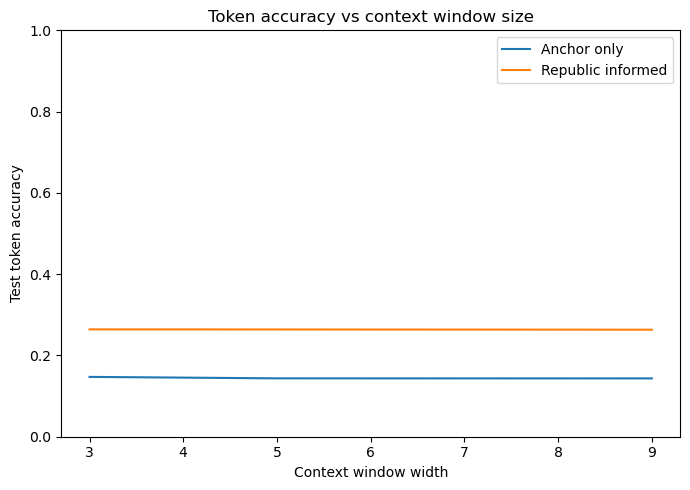

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\result images\token_accuracy_vs_context_window.png


In [19]:
context_sweep_rows = filtered_records(
    anchor_percentage=BASE_ANCHOR_PERCENTAGE,
    decoder_size=BASE_DECODER_SIZE,
)

save_line_plot(
    rows=context_sweep_rows,
    x_key="window_width",
    y_key="test_all_token_accuracy",
    xlabel="Context window width",
    ylabel="Test token accuracy",
    title="Token accuracy vs context window size",
    filename="token_accuracy_vs_context_window.png",
)

## Accuracy versus decoder size

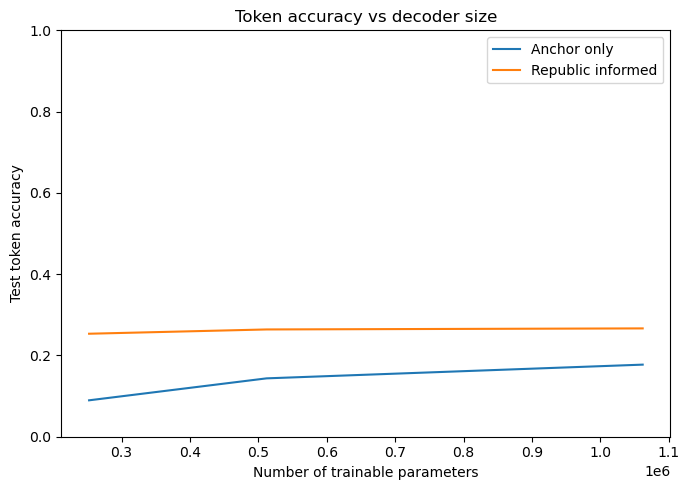

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\result images\token_accuracy_vs_decoder_parameters.png


In [20]:
size_sweep_rows = filtered_records(
    anchor_percentage=BASE_ANCHOR_PERCENTAGE,
    context_radius=BASE_CONTEXT_RADIUS,
)

save_line_plot(
    rows=size_sweep_rows,
    x_key="trainable_parameters",
    y_key="test_all_token_accuracy",
    xlabel="Number of trainable parameters",
    ylabel="Test token accuracy",
    title="Token accuracy vs decoder size",
    filename="token_accuracy_vs_decoder_parameters.png",
)

## Classical map recovery versus anchor percentage

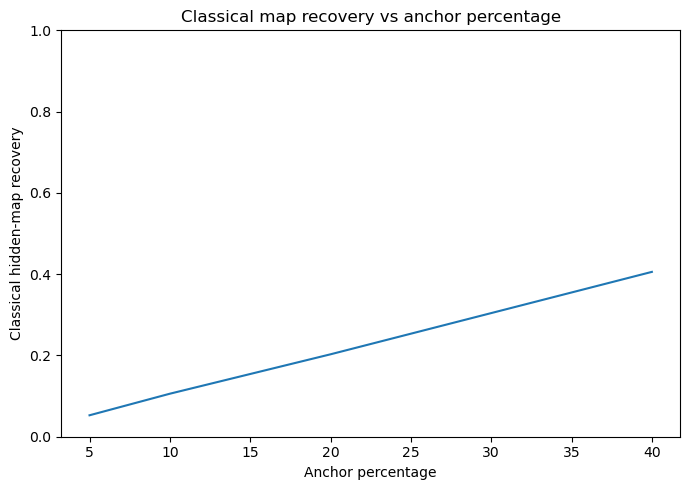

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\result images\classical_map_recovery_vs_anchor_percentage.png


In [21]:
# One classical result per anchor percentage is sufficient because
# the classical map does not depend on neural context radius or decoder size.
classical_rows = []

for percentage in ANCHOR_PERCENTAGES:
    row = next(
        record
        for record in evaluation_records
        if (
            record["method"]
            == "republic_informed"
            and int(record["anchor_percentage"])
            == percentage
            and int(record["context_radius"])
            == BASE_CONTEXT_RADIUS
            and record["decoder_size"]
            == BASE_DECODER_SIZE
        )
    )

    classical_rows.append(row)

plt.figure(figsize=(7, 5))

plt.plot(
    [
        row["anchor_percentage"]
        for row in classical_rows
    ],
    [
        row["classical_map_recovery_all_K"]
        for row in classical_rows
    ],
)

plt.xlabel("Anchor percentage")
plt.ylabel("Classical hidden-map recovery")
plt.title("Classical map recovery vs anchor percentage")
plt.ylim(0.0, 1.0)
plt.tight_layout()

classical_plot_path = (
    RESULT_IMAGE_DIR
    / "classical_map_recovery_vs_anchor_percentage.png"
)

plt.savefig(
    classical_plot_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
print("Saved:", classical_plot_path.resolve())

# Step 10: Failure analysis

The following analysis uses a predeclared reference configuration:

- 20% anchors,
- context radius $$m=2$$,
- medium decoder,
- Republic-informed two-stage method.

This configuration was chosen before test evaluation, not because it achieved the best test result.

We examine:

- anchored versus unanchored occurrences,
- source syllables that do versus do not appear in *The Republic*,
- low-frequency versus high-frequency glyphs,
- the observed effects of anchor percentage,
- the observed effects of context size,
- the observed effects of decoder size.

We do not retrain after this analysis.

In [22]:
REFERENCE_CONFIG = {
    "method": "republic_informed",
    "anchor_percentage": BASE_ANCHOR_PERCENTAGE,
    "context_radius": BASE_CONTEXT_RADIUS,
    "decoder_size": BASE_DECODER_SIZE,
}

reference_record = next(
    row
    for row in training_records
    if (
        row["method"]
        == REFERENCE_CONFIG["method"]
        and int(row["anchor_percentage"])
        == REFERENCE_CONFIG["anchor_percentage"]
        and int(row["context_radius"])
        == REFERENCE_CONFIG["context_radius"]
        and row["decoder_size"]
        == REFERENCE_CONFIG["decoder_size"]
    )
)

reference_model = load_saved_model(
    reference_record
)

ref_center_glyphs, ref_predictions = predict_test(
    reference_model,
    BASE_CONTEXT_RADIUS,
)

ref_truth = true_inverse_map[
    ref_center_glyphs
]

ref_correct = (
    ref_predictions == ref_truth
)

reference_anchor_glyphs = set(
    anchor_maps[
        BASE_ANCHOR_PERCENTAGE
    ]
)

is_anchored_occurrence = np.asarray(
    [
        int(glyph_id)
        in reference_anchor_glyphs
        for glyph_id in ref_center_glyphs
    ],
    dtype=bool,
)

truth_seen_in_republic = (
    reference_frequency[
        ref_truth
    ]
    > 0
)

center_train_frequency = (
    training_glyph_frequency[
        ref_center_glyphs
    ]
)

positive_training_frequencies = (
    training_glyph_frequency[
        training_glyph_frequency > 0
    ]
)

q25, q50, q75 = np.quantile(
    positive_training_frequencies,
    [0.25, 0.50, 0.75],
)


def frequency_group(count):
    if count <= q25:
        return "lowest frequency quartile"
    if count <= q50:
        return "second frequency quartile"
    if count <= q75:
        return "third frequency quartile"
    return "highest frequency quartile"


frequency_groups = np.asarray(
    [
        frequency_group(count)
        for count in center_train_frequency
    ],
    dtype=object,
)

failure_rows = []

def add_group_result(category, group, mask):
    if not np.any(mask):
        return

    failure_rows.append({
        "category": category,
        "group": group,
        "positions": int(mask.sum()),
        "accuracy": float(
            np.mean(
                ref_correct[mask]
            )
        ),
    })


add_group_result(
    "anchor_status",
    "anchored",
    is_anchored_occurrence,
)

add_group_result(
    "anchor_status",
    "unanchored",
    ~is_anchored_occurrence,
)

add_group_result(
    "reference_coverage",
    "true syllable appears in Republic",
    truth_seen_in_republic,
)

add_group_result(
    "reference_coverage",
    "true syllable absent from Republic",
    ~truth_seen_in_republic,
)

for group in [
    "lowest frequency quartile",
    "second frequency quartile",
    "third frequency quartile",
    "highest frequency quartile",
]:
    add_group_result(
        "training_glyph_frequency",
        group,
        frequency_groups == group,
    )


FAILURE_TABLE_PATH = DATA_DIR / "task10_failure_analysis.csv"

with FAILURE_TABLE_PATH.open(
    "w",
    newline="",
    encoding="utf-8",
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "category",
            "group",
            "positions",
            "accuracy",
        ],
    )
    writer.writeheader()
    writer.writerows(failure_rows)

for row in failure_rows:
    print(
        f"{row['category']:<26} "
        f"{row['group']:<38} "
        f"n={row['positions']:<8,} "
        f"accuracy={row['accuracy']:.4f}"
    )

print()
print("Saved:", FAILURE_TABLE_PATH.resolve())

anchor_status              anchored                               n=2,277    accuracy=0.9600
anchor_status              unanchored                             n=9,308    accuracy=0.0937
reference_coverage         true syllable appears in Republic      n=11,256   accuracy=0.2657
reference_coverage         true syllable absent from Republic     n=329      accuracy=0.2036
training_glyph_frequency   lowest frequency quartile              n=416      accuracy=0.0048
training_glyph_frequency   second frequency quartile              n=126      accuracy=0.1270
training_glyph_frequency   third frequency quartile               n=588      accuracy=0.1820
training_glyph_frequency   highest frequency quartile             n=10,455   accuracy=0.2805

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\data\task10_failure_analysis.csv


## Summarize observed effects without adding untested claims

In [23]:
def get_eval(
    method,
    anchor_percentage,
    context_radius,
    decoder_size,
):
    return next(
        row
        for row in evaluation_records
        if (
            row["method"] == method
            and int(row["anchor_percentage"])
            == anchor_percentage
            and int(row["context_radius"])
            == context_radius
            and row["decoder_size"]
            == decoder_size
        )
    )


observed_lines = []

anchor_5 = get_eval(
    "republic_informed",
    5,
    BASE_CONTEXT_RADIUS,
    BASE_DECODER_SIZE,
)

anchor_40 = get_eval(
    "republic_informed",
    40,
    BASE_CONTEXT_RADIUS,
    BASE_DECODER_SIZE,
)

anchor_change = (
    anchor_40["test_unanchored_token_accuracy"]
    - anchor_5["test_unanchored_token_accuracy"]
)

observed_lines.append(
    "Anchor percentage was tested directly. "
    f"Republic-informed unanchored test accuracy changed by "
    f"{anchor_change:+.4f} from 5% to 40% anchors."
)

context_values = []

for m in CONTEXT_RADII:
    row = get_eval(
        "republic_informed",
        BASE_ANCHOR_PERCENTAGE,
        m,
        BASE_DECODER_SIZE,
    )
    context_values.append(
        row["test_all_token_accuracy"]
    )

observed_lines.append(
    "Context-window size was tested directly. "
    f"Across the tested context radii, all-token accuracy ranged from "
    f"{min(context_values):.4f} to {max(context_values):.4f}."
)

size_values = []

for size_name in DECODER_SIZES:
    row = get_eval(
        "republic_informed",
        BASE_ANCHOR_PERCENTAGE,
        BASE_CONTEXT_RADIUS,
        size_name,
    )
    size_values.append(
        row["test_all_token_accuracy"]
    )

observed_lines.append(
    "Decoder size was tested directly. "
    f"Across the tested decoder sizes, all-token accuracy ranged from "
    f"{min(size_values):.4f} to {max(size_values):.4f}."
)

coverage_rows = {
    row["group"]: row
    for row in failure_rows
    if row["category"] == "reference_coverage"
}

if (
    "true syllable appears in Republic"
    in coverage_rows
    and
    "true syllable absent from Republic"
    in coverage_rows
):
    seen_acc = coverage_rows[
        "true syllable appears in Republic"
    ]["accuracy"]

    missing_acc = coverage_rows[
        "true syllable absent from Republic"
    ]["accuracy"]

    observed_lines.append(
        "Reference-corpus coverage was observed directly. "
        f"Accuracy was {seen_acc:.4f} when the true syllable appeared "
        f"in Republic and {missing_acc:.4f} when it did not."
    )

frequency_rows = {
    row["group"]: row
    for row in failure_rows
    if row["category"]
    == "training_glyph_frequency"
}

if (
    "lowest frequency quartile"
    in frequency_rows
    and
    "highest frequency quartile"
    in frequency_rows
):
    low_acc = frequency_rows[
        "lowest frequency quartile"
    ]["accuracy"]

    high_acc = frequency_rows[
        "highest frequency quartile"
    ]["accuracy"]

    observed_lines.append(
        "Glyph frequency was observed directly. "
        f"Accuracy was {low_acc:.4f} in the lowest training-frequency quartile "
        f"and {high_acc:.4f} in the highest quartile."
    )

print("Observed findings")
print("-----------------")

for line in observed_lines:
    print("-", line)

print()
print("Not tested by this experiment")
print("-----------------------------")
print("- Reducing the amount of glyph training text was not tested.")
print("- Replacing the syllable tokenizer with a different tokenization scheme was not tested.")
print("- Replacing The Republic with a different English reference corpus was not tested.")
print("- Therefore failures should not be attributed to those factors as established facts.")

Observed findings
-----------------
- Anchor percentage was tested directly. Republic-informed unanchored test accuracy changed by +0.1211 from 5% to 40% anchors.
- Context-window size was tested directly. Across the tested context radii, all-token accuracy ranged from 0.2634 to 0.2642.
- Decoder size was tested directly. Across the tested decoder sizes, all-token accuracy ranged from 0.2534 to 0.2666.
- Reference-corpus coverage was observed directly. Accuracy was 0.2657 when the true syllable appeared in Republic and 0.2036 when it did not.
- Glyph frequency was observed directly. Accuracy was 0.0048 in the lowest training-frequency quartile and 0.2805 in the highest quartile.

Not tested by this experiment
-----------------------------
- Reducing the amount of glyph training text was not tested.
- Replacing the syllable tokenizer with a different tokenization scheme was not tested.
- Replacing The Republic with a different English reference corpus was not tested.
- Therefore failure

## Successful and failed token examples from the fixed reference configuration

In [24]:
example_rows = []

correct_indices = np.flatnonzero(
    ref_correct
)[:10]

incorrect_indices = np.flatnonzero(
    ~ref_correct
)[:10]

for status, indices in [
    ("correct", correct_indices),
    ("incorrect", incorrect_indices),
]:
    for index in indices:
        glyph_id = int(
            ref_center_glyphs[index]
        )

        predicted_id = int(
            ref_predictions[index]
        )

        true_id = int(
            ref_truth[index]
        )

        example_rows.append({
            "status": status,
            "glyph_id": glyph_id,
            "anchored": (
                glyph_id
                in reference_anchor_glyphs
            ),
            "predicted_source_id": predicted_id,
            "predicted_syllable": syllable_by_source_id[predicted_id],
            "true_source_id": true_id,
            "true_syllable": syllable_by_source_id[true_id],
        })


EXAMPLE_PATH = DATA_DIR / "task10_success_failure_examples.csv"

with EXAMPLE_PATH.open(
    "w",
    newline="",
    encoding="utf-8",
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(
            example_rows[0].keys()
        ),
    )
    writer.writeheader()
    writer.writerows(example_rows)

for row in example_rows:
    print(
        f"{row['status']:<9} "
        f"glyph={row['glyph_id']:<6} "
        f"anchored={str(row['anchored']):<5} "
        f"pred={row['predicted_syllable']:<14} "
        f"true={row['true_syllable']}"
    )

print()
print("Saved:", EXAMPLE_PATH.resolve())

correct   glyph=36     anchored=True  pred=how            true=how
correct   glyph=2004   anchored=True  pred=be             true=be
correct   glyph=2550   anchored=True  pred=for            true=for
correct   glyph=2004   anchored=True  pred=be             true=be
correct   glyph=2004   anchored=True  pred=be             true=be
correct   glyph=1887   anchored=True  pred=to             true=to
correct   glyph=2004   anchored=True  pred=be             true=be
correct   glyph=2196   anchored=False pred=of             true=of
correct   glyph=679    anchored=True  pred=think          true=think
correct   glyph=2196   anchored=False pred=of             true=of
incorrect glyph=1915   anchored=False pred=both           true=many
incorrect glyph=2908   anchored=False pred=man            true=things
incorrect glyph=2437   anchored=False pred=al             true=there
incorrect glyph=2009   anchored=False pred=say            true=which
incorrect glyph=2437   anchored=False pred=al             t

## Successful and failed decoded passages

For the fixed reference configuration, evaluate every contiguous 20-token window of valid test centers. Select the earliest-starting window among ties for the maximum and minimum numbers of correct tokens, then expand the selected window to complete normalized word boundaries. This is a post-hoc illustration only and is not used for model selection. The resulting evidence is saved to `data/task10_decoded_passage_examples.csv`.

In [25]:
# Reconstruct readable evaluation-only passages from the saved source token sequence.
MEDITATIONS_TOKENIZATION_PATH = DATA_DIR / "meditations_tokenization_text.txt"
SOURCE_SEQUENCE_PATH = DATA_DIR / "meditations_syllable_token_sequence.csv"

source_syllables = []
with SOURCE_SEQUENCE_PATH.open("r", encoding="utf-8", newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        source_syllables.append(row["syllable"])

source_text = MEDITATIONS_TOKENIZATION_PATH.read_text(encoding="utf-8")
word_matches = list(re.finditer(r"[a-z]+", source_text))
word_records = []
token_cursor = 0
last_char = 0

for match in word_matches:
    word = match.group(0)
    separator_before = source_text[last_char:match.start()]
    token_start = token_cursor
    reconstructed = ""

    while token_cursor < len(source_syllables) and len(reconstructed) < len(word):
        reconstructed += source_syllables[token_cursor]
        token_cursor += 1

    if reconstructed != word:
        raise AssertionError(f"Word alignment failed for {word!r}")

    word_records.append({
        "token_start": token_start,
        "token_end": token_cursor - 1,
        "word": word,
        "separator_before": separator_before,
        "char_start": match.start(),
        "char_end": match.end(),
    })
    last_char = match.end()

assert token_cursor == len(source_syllables)

word_of_token = np.empty(len(source_syllables), dtype=np.int64)
for word_index, record in enumerate(word_records):
    word_of_token[record["token_start"]:record["token_end"] + 1] = word_index

# The reference prediction arrays already exclude m tokens at each test boundary.
raw_width = 20
raw_scores = np.convolve(ref_correct.astype(np.int64), np.ones(raw_width, dtype=np.int64), mode="valid")
max_starts = np.flatnonzero(raw_scores == raw_scores.max())
min_starts = np.flatnonzero(raw_scores == raw_scores.min())

original_positions = []
with TEST_PATH.open("r", encoding="utf-8", newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        original_positions.append(int(row["original_position"]))
original_positions = np.asarray(original_positions, dtype=np.int64)
original_to_test = {int(g): i for i, g in enumerate(original_positions)}

passage_rows = []
for passage_type, start_index, tie_count in [
    ("successful", int(max_starts[0]), len(max_starts)),
    ("failed", int(min_starts[0]), len(min_starts)),
]:
    raw_test_start = int(start_index + BASE_CONTEXT_RADIUS)
    raw_test_end = raw_test_start + raw_width - 1
    raw_global_start = int(original_positions[raw_test_start])
    raw_global_end = int(original_positions[raw_test_end])

    first_word = int(word_of_token[raw_global_start])
    last_word = int(word_of_token[raw_global_end])
    expanded_global_start = int(word_records[first_word]["token_start"])
    expanded_global_end = int(word_records[last_word]["token_end"])

    expanded_test_start = original_to_test[expanded_global_start]
    expanded_test_end = original_to_test[expanded_global_end]
    pred_start = expanded_test_start - BASE_CONTEXT_RADIUS
    pred_end = expanded_test_end - BASE_CONTEXT_RADIUS

    expanded_predictions = ref_predictions[pred_start:pred_end + 1]
    expanded_truth = ref_truth[pred_start:pred_end + 1]

    predicted_parts = []
    true_parts = []
    for wi in range(first_word, last_word + 1):
        wr = word_records[wi]
        test_start = original_to_test[int(wr["token_start"])]
        p0 = test_start - BASE_CONTEXT_RADIUS
        n_tokens = int(wr["token_end"] - wr["token_start"] + 1)
        ids = ref_predictions[p0:p0 + n_tokens]
        predicted_parts.append(
            wr["separator_before"]
            + "".join(syllable_by_source_id[int(x)] for x in ids)
        )
        true_parts.append(wr["separator_before"] + wr["word"])

    after_start = word_records[last_word]["char_end"]
    after_end = (
        word_records[last_word + 1]["char_start"]
        if last_word + 1 < len(word_records)
        else len(source_text)
    )
    trailing_separator = source_text[after_start:after_end]

    passage_rows.append({
        "passage_type": passage_type,
        "selection_tie_break": "earliest starting window among ties",
        "number_of_tied_raw_windows": int(tie_count),
        "raw_window_start_global_token": raw_global_start,
        "raw_window_end_global_token": raw_global_end,
        "raw_window_correct_tokens": int(raw_scores[start_index]),
        "raw_window_tokens": raw_width,
        "raw_window_accuracy": float(raw_scores[start_index] / raw_width),
        "expanded_start_global_token": expanded_global_start,
        "expanded_end_global_token": expanded_global_end,
        "expanded_correct_tokens": int(np.sum(expanded_predictions == expanded_truth)),
        "expanded_tokens": int(len(expanded_predictions)),
        "expanded_accuracy": float(np.mean(expanded_predictions == expanded_truth)),
        "decoded_prediction": ("".join(predicted_parts) + trailing_separator).strip(),
        "true_plaintext": ("".join(true_parts) + trailing_separator).strip(),
    })

PASSAGE_PATH = DATA_DIR / "task10_decoded_passage_examples.csv"
with PASSAGE_PATH.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(passage_rows[0].keys()))
    writer.writeheader()
    writer.writerows(passage_rows)

for row in passage_rows:
    print()
    print(row["passage_type"].upper())
    print(f"Raw 20-token window: {row['raw_window_correct_tokens']}/20")
    print(f"Expanded passage: {row['expanded_correct_tokens']}/{row['expanded_tokens']} = {row['expanded_accuracy']:.2%}")
    print("Decoded:", row["decoded_prediction"])
    print("Truth:  ", row["true_plaintext"])

print("Saved:", PASSAGE_PATH.resolve())


SUCCESSFUL
Raw 20-token window: 12/20
Expanded passage: 12/20 = 60.00%
Decoded: to in nation of in universe?

men contemn per animi, and yet men seek to
Truth:   to the nature of the universe?

they contemn one another, and yet they seek to

FAILED
Raw 20-token window: 0/20
Expanded passage: 1/21 = 4.76%
Decoded: eithan per fect, not in imi fect, ing said ac powmoreca tions yesiwould, so the
Truth:   either one way, or the other way, is not any external thing properly, but that
Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW5.1\data\task10_decoded_passage_examples.csv


## Steps 6-10 outputs

### Data files

`data/`

- `task7_classical_inference_summary.csv`
- `task6_8_training_manifest.csv`
- `task9_evaluation_results.csv`
- `task10_failure_analysis.csv`
- `task10_success_failure_examples.csv`

### Derived candidate maps

`data/inferred_maps/`

- one Republic-informed candidate map for each anchor percentage.

These maps are derived only from permitted training information.

### Trained neural models

`data/trained_models/`

- saved anchor-only and Republic-informed MLP models for all unique experiment configurations.

### Result images

`result images/`

- `token_accuracy_vs_anchor_percentage.png`
- `unanchored_accuracy_vs_anchor_percentage.png`
- `map_recovery_vs_anchor_percentage.png`
- `token_accuracy_vs_context_window.png`
- `token_accuracy_vs_decoder_parameters.png`
- `classical_map_recovery_vs_anchor_percentage.png`

The notebook keeps classical substitution inference and neural decoder training explicitly separate, as required for the two-stage interpretation.